# 02 · Phase probing

**Question.** Chronos-Bolt sees only numbers, never timestamps. Does it know the time of day and the day of the week, and where in the network does that knowledge appear?

**Setup.** Synthetic hourly series with a daily (24 h) and a weekly (168 h) cycle, random starting phases, trend, scale and noise. Every patch token gets two labels: the true daily and weekly phase at its last time step.

**Method.** Linear probes for each phase at every layer, compared with two baselines: the raw normalised patch (what one token knows on its own) and an untrained copy of the model (what the architecture gives for free). Then the geometry: the 3D PCA view, the probe planes, and the torus.

**Result.** See the takeaways at the end.

## 1 · Setup

In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import torch
from chronos.chronos_bolt import ChronosBoltModelForForecasting
from ripser import ripser
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

from torus_clock.model import capture, load_model
from torus_clock.synthetic import P_DAY, P_WEEK, make_series

In [21]:
N_SERIES = 300   # number of synthetic series
T = 512          # context length (hours)
NOISE = 0.5      # noise std, relative to the daily amplitude
SEED = 0

RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

## 2 · Data

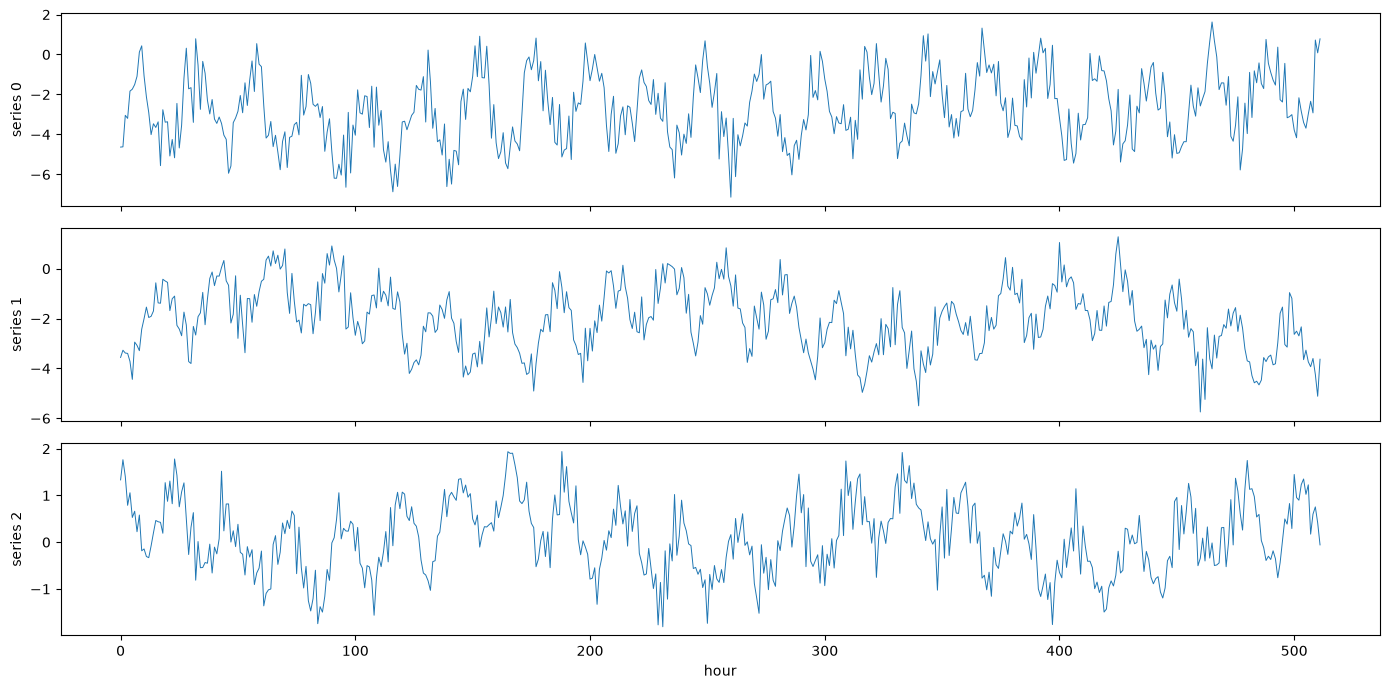

In [22]:
data = make_series(N_SERIES, T, noise=NOISE, seed=SEED)
x = data["x"]
t = np.arange(x.shape[1])

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for ax, k in zip(axes, [0, 1, 2]):
    ax.plot(t, x[k], lw=0.7)
    ax.set_ylabel(f"series {k}")
axes[-1].set_xlabel("hour")
plt.tight_layout()
plt.show()

## 3 · Activations

One forward pass each through the trained model and through an untrained copy (same architecture, fresh random weights). `capture` returns the residual stream at layer 0 (patch embeddings), after each encoder block (layers 1–6), and after the encoder's final norm (`encoder out`, what the decoder reads).

In [23]:
model = load_model()
torch.manual_seed(SEED)
untrained = ChronosBoltModelForForecasting(model.config).eval()

context = torch.tensor(x)
acts, out = capture(model, context)
acts_u, _ = capture(untrained, context)

PATCH = model.chronos_config.input_patch_size   # 16
N_PATCH = T // PATCH                            # 32
D = model.config.d_model                        # 512
LAYERS = list(acts)                             # "layer 0", ..., "layer 6", "encoder out"
print(LAYERS, out.quantile_preds.shape)

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 5185.67it/s]


['layer 0', 'layer 1', 'layer 2', 'layer 3', 'layer 4', 'layer 5', 'layer 6', 'encoder out'] torch.Size([300, 9, 64])


## 4 · Labels and split

Patch $j$ covers hours $16j$ to $16j+15$. Its label is the phase at its **last** hour. Rows of the flattened arrays are ordered series by series: series $k$ is rows $32k$ to $32k+31$.

The train/test split is **by series**, so a probe can't memorise a series it is tested on.

In [24]:
patch_end = PATCH * np.arange(N_PATCH) + PATCH - 1
daily = data["daily_phase"][:, patch_end]     # [N_SERIES, N_PATCH]
weekly = data["weekly_phase"][:, patch_end]

# consecutive patches are 16 h apart
assert np.allclose(np.mod(daily[:, 1] - daily[:, 0], 2 * np.pi), 2 * np.pi * PATCH / P_DAY)
assert np.allclose(np.mod(weekly[:, 1] - weekly[:, 0], 2 * np.pi), 2 * np.pi * PATCH / P_WEEK)

y_daily = daily.reshape(-1)                   # [N_SERIES * N_PATCH]
y_weekly = weekly.reshape(-1)

rng = np.random.default_rng(SEED)
series = rng.permutation(N_SERIES)
n_train = int(0.7 * N_SERIES)


def rows(s):
    # row indices, in the flattened arrays, of the given series
    return (s[:, None] * N_PATCH + np.arange(N_PATCH)).ravel()


tr, te = rows(series[:n_train]), rows(series[n_train:])

In [25]:
print(tr)
print(te)

[1152 1153 1154 ... 6845 6846 6847]
[1216 1217 1218 ... 3069 3070 3071]


## 5 · Probes

A linear probe predicts $(\cos\theta, \sin\theta)$ from a token's vector with ridge regression, and reads the angle back with `atan2`. Scores on held-out series:

- **score** = mean $\cos(\text{error})$: 1 is perfect, 0 is chance
- **err h** = median absolute error, in hours

In [26]:
def tokens(acts, layer):
    # patch tokens of one layer, without [REG]: [N_SERIES * N_PATCH, D]
    return acts[layer][:, :N_PATCH].cpu().numpy().reshape(-1, D)


def fit_probe(X, y):
    # fit on training series; returns a function mapping token vectors to (cos, sin) estimates
    scaler = StandardScaler().fit(X[tr])
    reg = RidgeCV(alphas=np.logspace(-1, 5, 13))
    reg.fit(scaler.transform(X[tr]), np.c_[np.cos(y[tr]), np.sin(y[tr])])
    return lambda Z: reg.predict(scaler.transform(Z))


def wrap(a):
    return np.angle(np.exp(1j * a))   # to (-pi, pi]


def probe(X, y, period):
    pred = fit_probe(X, y)(X[te])
    err = wrap(np.arctan2(pred[:, 1], pred[:, 0]) - y[te])
    return np.mean(np.cos(err)), np.median(np.abs(err)) * period / (2 * np.pi)

In [27]:
raw = (x - x.mean(1, keepdims=True)) / x.std(1, keepdims=True)   # same normalisation as the model
reps = {("baseline", "raw patch"): raw.reshape(-1, PATCH)}
reps.update({("trained", name): tokens(acts, name) for name in LAYERS})
reps.update({("untrained", name): tokens(acts_u, name) for name in LAYERS})

records = []
for (which, layer), X in reps.items():
    d, de = probe(X, y_daily, P_DAY)
    w, we = probe(X, y_weekly, P_WEEK)
    records.append({"model": which, "layer": layer,
                    "daily": d, "daily err h": de, "weekly": w, "weekly err h": we})

scores = pd.DataFrame(records).set_index(["model", "layer"])
scores.to_csv(RESULTS / "02_probe_scores.csv")
scores.round(3)

daily  daily err h  weekly  weekly err h
model     layer                                                
baseline  raw patch    0.973        0.575   0.559        18.532
trained   layer 0      0.972        0.587   0.599        16.534
          layer 1      0.996        0.210   0.956         3.785
          layer 2      0.998        0.154   0.976         3.140
          layer 3      0.998        0.151   0.987         2.542
          layer 4      0.998        0.145   0.991         2.210
          layer 5      0.998        0.149   0.991         2.100
          layer 6      0.998        0.148   0.992         2.048
          encoder out  0.998        0.160   0.992         2.023
untrained layer 0      0.972        0.596   0.590        17.430
          layer 1      0.972        0.596   0.590        17.431
          layer 2      0.972        0.596   0.590        17.431
          layer 3      0.972        0.596   0.590        17.430
          layer 4      0.972        0.596   0.590        17.431
          layer 5      0.972        0.596   0.590        17.431
          layer 6      0.972        0.596   0.590        17.431
          encoder out  0.972        0.589   0.591        17.318

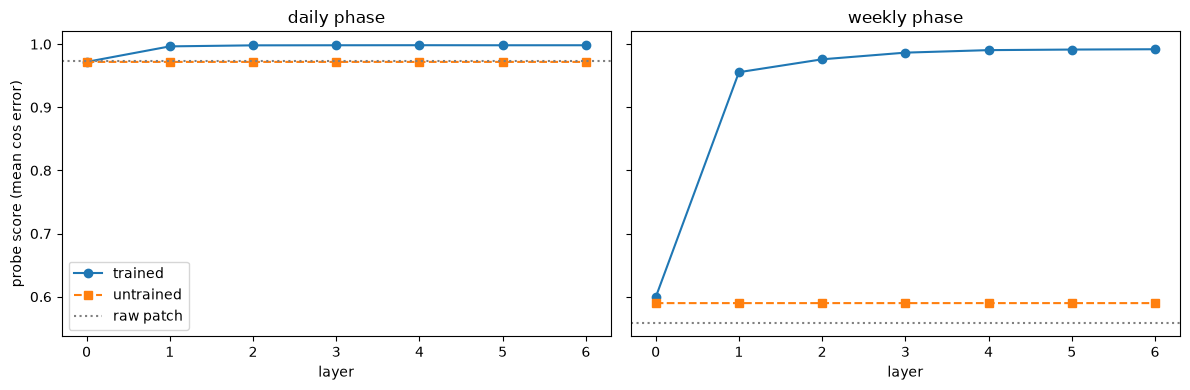

In [28]:
layer_ids = [n for n in LAYERS if n.startswith("layer")]
xs = np.arange(len(layer_ids))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, phase in zip(axes, ["daily", "weekly"]):
    for which, style in [("trained", "-o"), ("untrained", "--s")]:
        ax.plot(xs, scores.loc[which].loc[layer_ids, phase], style, label=which)
    ax.axhline(scores.loc[("baseline", "raw patch"), phase], color="gray", ls=":", label="raw patch")
    ax.set_xticks(xs, [n.split()[-1] for n in layer_ids])
    ax.set_xlabel("layer")
    ax.set_title(f"{phase} phase")
axes[0].set_ylabel("probe score (mean cos error)")
axes[0].legend()
plt.tight_layout()
plt.savefig(RESULTS / "02_probe_scores.png", dpi=150)
plt.show()

## 6 · Geometry

### 6.1 · PCA in 3D

The daily circle carries the most variance, so it takes PC1–PC2. PC3 holds one axis of the weekly plane. Projecting a circle onto a single axis squashes it to a segment, so a torus seen this way is a **cylinder**: circle × segment. Plots are written as HTML (open them in a browser).

In [29]:
X4 = tokens(acts, "layer 4")
P = PCA(n_components=3).fit_transform(X4)

for phase, y in [("daily", y_daily), ("weekly", y_weekly)]:
    fig = px.scatter_3d(x=P[:, 0], y=P[:, 1], z=P[:, 2], color=y,
                        color_continuous_scale="twilight", opacity=0.6,
                        title=f"layer 4, PCA, coloured by {phase} phase")
    fig.update_traces(marker_size=2)
    fig.write_html(RESULTS / f"02_layer4_pca3d_{phase}.html")

### 6.2 · Probe planes

Each probe is a linear map onto a 2D plane, $(\hat c, \hat s)$. Unlike PCA, the angle in that plane *means* the phase, so the pictures line up across layers. Distance from the centre shows how sure the layer is.

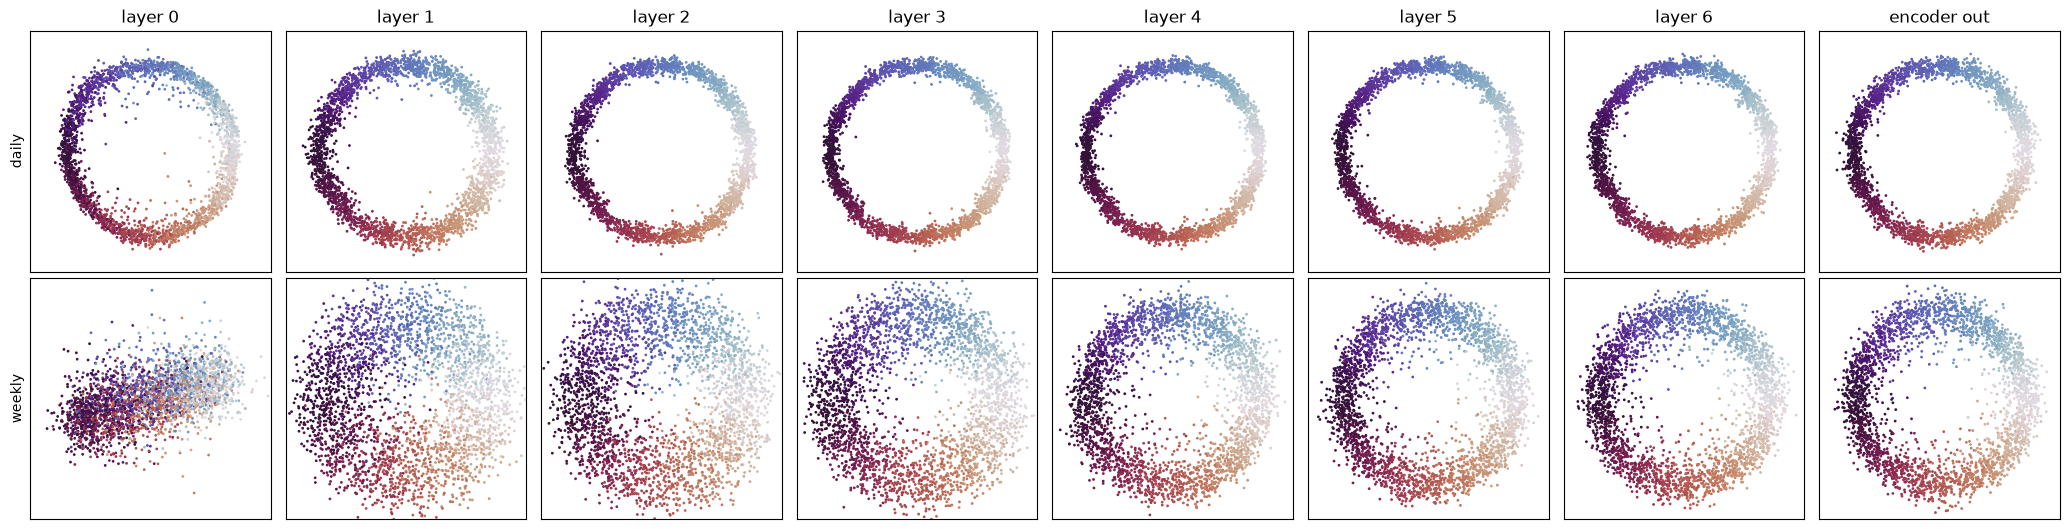

In [30]:
fig, axes = plt.subplots(2, len(LAYERS), figsize=(2.6 * len(LAYERS), 5.4))
for col, layer in enumerate(LAYERS):
    X = tokens(acts, layer)
    for row, (phase, y) in enumerate([("daily", y_daily), ("weekly", y_weekly)]):
        C = fit_probe(X, y)(X[te])
        ax = axes[row, col]
        ax.scatter(C[:, 0], C[:, 1], c=y[te], cmap="twilight", vmin=0, vmax=2 * np.pi, s=1)
        ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(layer)
        if col == 0:
            ax.set_ylabel(phase)
plt.tight_layout()
plt.savefig(RESULTS / "02_probe_planes.png", dpi=150)
plt.show()

### 6.3 · The torus

Daily and weekly coordinates together give each token a point in $\mathbb{R}^4$, near $(\cos\theta, \sin\theta, \cos\omega, \sin\omega)$: a flat torus. To draw it in 3D we use the ring-torus map

$$(\theta, \omega) \mapsto \big((R + r\rho\cos\omega)\cos\theta,\ (R + r\rho\cos\omega)\sin\theta,\ r\rho\sin\omega\big)$$

where $\rho$ is the token's distance from the centre of the weekly plane. **This picture assumes the shape**: any two angles would make a donut. What it shows is how the tokens spread over it. The untrained model is the control.

In [31]:
def torus_xyz(acts, layer, R=3.0, r=1.0):
    X = tokens(acts, layer)
    d = fit_probe(X, y_daily)(X[te])
    w = fit_probe(X, y_weekly)(X[te])
    th, om = np.arctan2(d[:, 1], d[:, 0]), np.arctan2(w[:, 1], w[:, 0])
    rho = np.linalg.norm(w, axis=1)
    return np.c_[(R + r * rho * np.cos(om)) * np.cos(th),
                 (R + r * rho * np.cos(om)) * np.sin(th),
                 r * rho * np.sin(om)]


for which, a in [("trained", acts), ("untrained", acts_u)]:
    xyz = torus_xyz(a, "layer 4")
    fig = px.scatter_3d(x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2], color=y_weekly[te],
                        color_continuous_scale="twilight", opacity=0.6,
                        title=f"{which}, layer 4, coloured by weekly phase")
    fig.update_traces(marker_size=2)
    fig.update_layout(scene_aspectmode="data")
    fig.write_html(RESULTS / f"02_torus_{which}.html")

### 6.4 · Persistent homology

The check that does **not** assume the shape. Average the 4D probe coordinates over cells of (time of day, day of week), then compute Vietoris–Rips persistence. A torus has Betti numbers $(b_0, b_1, b_2) = (1, 2, 1)$: one component, two independent loops, one enclosed cavity. So we expect two long $H_1$ bars and one long $H_2$ bar.

In [32]:
def torus_homology(acts, layer, n_day=12, n_week=14):
    X = tokens(acts, layer)
    Z = np.c_[fit_probe(X, y_daily)(X), fit_probe(X, y_weekly)(X)]   # [rows, 4]
    db = (y_daily / (2 * np.pi) * n_day).astype(int) % n_day
    wb = (y_weekly / (2 * np.pi) * n_week).astype(int) % n_week
    cells = [(a, b) for a in range(n_day) for b in range(n_week) if np.any((db == a) & (wb == b))]
    C = np.stack([Z[(db == a) & (wb == b)].mean(0) for a, b in cells])
    dgms = ripser(C, maxdim=2)["dgms"]
    return {f"H{k}": np.sort((dg[:, 1] - dg[:, 0])[np.isfinite(dg[:, 1])])[::-1][:4].round(2)
            for k, dg in enumerate(dgms)}


for which, a in [("trained", acts), ("untrained", acts_u)]:
    print(which, torus_homology(a, "layer 4"))

trained {'H0': array([0.49, 0.49, 0.49, 0.48]), 'H1': array([1.21, 1.2 , 0.24, 0.23]), 'H2': array([1.06, 0.18, 0.17, 0.16])}
untrained {'H0': array([0.37, 0.36, 0.35, 0.33]), 'H1': array([1.2 , 0.14, 0.13, 0.12]), 'H2': array([0.09, 0.09, 0.06, 0.05])}


## 7 · Takeaways

Rerun the notebook to refresh the numbers; with `NOISE = 0.5` the run on 6 November gave:

| | daily | weekly |
|---|---|---|
| raw patch | 0.97, ±0.6 h | 0.56, ±19 h |
| trained, layer 1 | 0.996, ±0.2 h | 0.96, ±4 h |
| trained, layers 4–6 | 0.998, ±0.15 h | 0.99, ±2 h |
| untrained, any layer | 0.97, ±0.6 h | 0.58, ±18 h |

- **The weekly clock is built by the encoder.** One patch can't show the day of the week. The first block brings the error from about 19 h to 4 h, and later blocks refine it to 2 h.
- **The daily clock is inherited, then sharpened.** A patch already shows most of a day; the encoder cuts the error by about 4×.
- **It's learned.** The untrained model never beats a single patch.
- **Shape.** Daily and weekly coordinates form a torus (check the persistent homology output above).

**Next:** steering. Rotate the weekly circle and check that the forecast moves as if it were another day.